### **Session 3 — Training that Generalizes**
### Deep Learning · Working with ANNs/MLPs (Part 2) · Lab 3

This notebook follows the class **in the same order as the slides**. One running example, a bank that wants to know
**which customers will leave (churn)** and **which product to offer next**, carries us through every idea:

| Part | Topic | What you will *see* |
|---|---|---|
| 1 | The running example | the data, the preparation pipeline, the accuracy trap |
| 2 | Binary classification | sigmoid, binary cross-entropy, why not MSE, the first network |
| 3 | Multiclass classification | softmax step by step, categorical cross-entropy, the gradient $p-y$ |
| 4 | Deep networks that train | activations, vanishing gradients (measured), weight initialization |
| 5 | Optimizers | SGD, momentum, RMSprop, Adam on a valley and on churn; learning-rate schedules |
| 6 | Training that generalizes | under/over-fitting, L2, dropout, batch normalization |
| 7 | Evaluating imbalanced data | confusion matrix, precision/recall, ROC and PR, class weights, a threshold chosen with money |
| 8 | Tools and baseline | callbacks, TensorBoard, comparison with XGBoost |

Each part ends with a **Recap** box that links it to the next one, and a **Try it** cell for you to change.

> **Runs on Google Colab or Kaggle** (CPU is enough, about 5–8 minutes in total).
> If you upload `Churn_Modelling.csv` (Kaggle *Churn Modelling* dataset) next to the notebook, the real data is used.
> Otherwise the notebook generates a simulated copy with the same columns, the one used in the slides.

<a target="_blank" href="https://colab.research.google.com/github/castorgit/DL-Course/blob/main/00-LAB-Session3_Training_that_Generalizes v1.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

---
## 0. Setup

In [1]:
import os, time, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import keras
from keras import layers, regularizers

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, roc_curve, precision_recall_curve, confusion_matrix,
                             accuracy_score, log_loss, average_precision_score)

print("Keras", keras.__version__, "| backend:", keras.backend.backend())
SEED = 42
keras.utils.set_random_seed(SEED)

# course palette
PURPLE, PLUM, ORANGE, TEAL, GREY, LILAC = "#7D3CA0", "#6E1E5F", "#EB7828", "#008C8C", "#787878", "#E9D6F0"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

I0000 00:00:1791967155.094104  100023 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791967155.133200  100023 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791967155.992751  100023 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Keras 3.12.3 | backend: tensorflow


In [2]:
# helpers used all along the notebook
def plot_history(h, metric="auc", title=""):
    # training vs validation curves for the loss and one metric
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
    for a, m in zip(ax, ["loss", metric]):
        a.plot(h.history[m], color=TEAL, lw=2, label="training")
        a.plot(h.history["val_" + m], color=ORANGE, lw=2, label="validation")
        a.set_xlabel("epoch"); a.set_title(m); a.legend()
    fig.suptitle(title); plt.tight_layout(); plt.show()

def bars(ax, values, labels, colors, title="", ylim=None, fmt="{:.2f}"):
    b = ax.bar(labels, values, color=colors)
    for r, v in zip(b, values):
        ax.text(r.get_x() + r.get_width()/2, v, fmt.format(v), ha="center",
                va="bottom" if v >= 0 else "top", fontsize=9)
    ax.set_title(title)
    if ylim: ax.set_ylim(*ylim)
    ax.tick_params(axis="x", rotation=25)

---
## Part 1 — The running example: customer churn

A European bank loses customers. Each customer who leaves costs about **500 EUR** of future margin; a retention offer
(a call, a fee waiver) costs about **50 EUR**. The question: **who should receive an offer this month?**

We will solve two tasks with the same customers:
* **Binary**: will the customer leave? (`Exited` = 0/1)
* **Multiclass**: which of 4 products should we offer next? (Savings, Credit card, Mortgage, Investment fund)

### 1.1 Get the data

In [3]:
GEO, PRODUCTS = ["France", "Germany", "Spain"], ["Savings", "Credit card", "Mortgage", "Investment"]

def simulate_customers(n=10000, seed=7):
    # same columns as the Kaggle 'Churn Modelling' dataset; churn depends non-linearly on age, products, activity
    r = np.random.default_rng(seed)
    df = pd.DataFrame({
        "CreditScore": np.clip(r.normal(650, 97, n), 350, 850).round(),
        "Geography": r.choice(GEO, n, p=[0.5, 0.25, 0.25]),
        "Gender": r.choice(["Male", "Female"], n, p=[0.55, 0.45]),
        "Age": np.clip(18 + r.gamma(4.5, 4.6, n), 18, 92).round(),
        "Tenure": r.integers(0, 11, n),
        "Balance": np.where(r.random(n) < 0.36, 0.0, np.clip(r.normal(120000, 30000, n), 1000, None)).round(2),
        "NumOfProducts": r.choice([1, 2, 3, 4], n, p=[0.50, 0.46, 0.03, 0.01]),
        "HasCrCard": (r.random(n) < 0.70).astype(int),
        "IsActiveMember": (r.random(n) < 0.51).astype(int),
        "EstimatedSalary": r.uniform(1000, 200000, n).round(2)})
    a = df.Age.values
    logit = 1.45 * (-2.75 + 1.9 * np.exp(-((a - 53) / 9.0) ** 2)
                    + np.select([df.NumOfProducts == 1, df.NumOfProducts == 2, df.NumOfProducts == 3], [0.35, -1.35, 2.2], 3.6)
                    + 0.75 * (df.Geography == "Germany") + 0.45 * (df.Gender == "Female")
                    + 0.85 * (1 - df.IsActiveMember) + 0.55 * ((1 - df.IsActiveMember) * (a > 45))
                    + 0.30 * (df.Balance > 0) - 0.0012 * (df.CreditScore - 650))
    df["Exited"] = (r.random(n) < 1 / (1 + np.exp(-logit))).astype(int)
    return df

def add_next_product(df, seed=8):
    # simulated 'next product' label (4 classes) from age, salary, balance and tenure
    r = np.random.default_rng(seed)
    a, sal, bal = df.Age.values, df.EstimatedSalary.values / 1e5, df.Balance.values / 1e5
    L = 1.6 * np.stack([1.0 - 0.02 * (a - 40) - 0.6 * sal,
                        0.4 - 0.05 * (a - 35) + 0.4 * df.IsActiveMember,
                        -1.3 + 1.6 * np.exp(-((a - 37) / 7) ** 2) + 0.9 * sal,
                        -1.2 + 0.05 * (a - 40) + 1.4 * bal + 0.3 * (df.Tenure / 10)], 1)
    P = np.exp(L - L.max(1, keepdims=True)); P /= P.sum(1, keepdims=True)
    df["NextProduct"] = [r.choice(4, p=p) for p in P]
    return df

if os.path.exists("Churn_Modelling.csv"):
    df = pd.read_csv("Churn_Modelling.csv").drop(columns=["RowNumber", "CustomerId", "Surname"])
    SOURCE = "real Kaggle data"
else:
    df = simulate_customers()
    SOURCE = "simulated data (same columns as Kaggle)"
df = add_next_product(df)
print(f"{len(df):,} customers, {SOURCE}")
df.head()

10,000 customers, simulated data (same columns as Kaggle)


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,NextProduct
0,650.0,France,Male,28.0,3,135905.74,1,1,1,126202.19,0,1
1,679.0,Spain,Male,37.0,2,144662.20,2,1,1,83561.82,0,3
2,623.0,France,Female,41.0,5,0.00,2,1,1,3551.24,0,0
3,564.0,Spain,Male,45.0,1,117105.45,2,1,1,2794.66,0,3
4,606.0,Germany,Male,32.0,7,116647.83,2,1,1,40057.84,0,2


### 1.2 Look at the data first
Before any model: how many customers leave, and what does churn depend on?

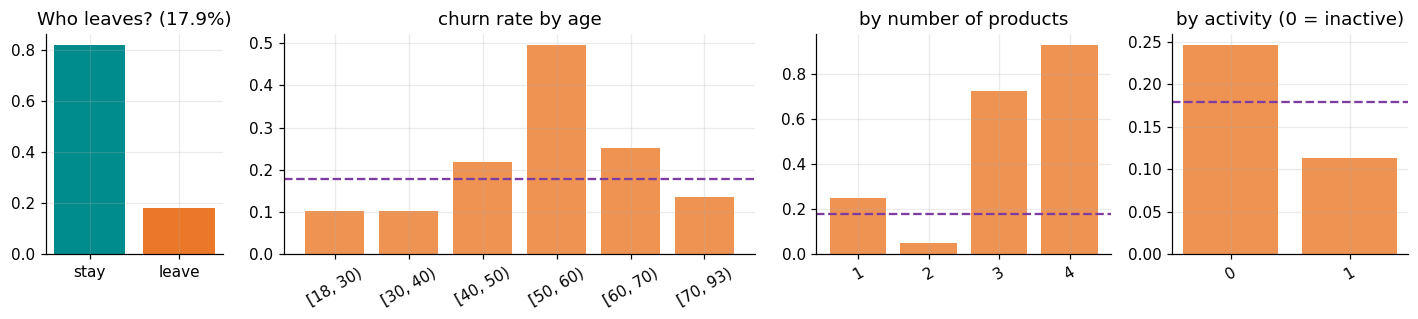

In [4]:
rate = df.Exited.mean()
fig, ax = plt.subplots(1, 4, figsize=(13, 3), gridspec_kw={"width_ratios": [0.6, 1.6, 1, 0.8]})
ax[0].bar(["stay", "leave"], [1 - rate, rate], color=[TEAL, ORANGE]); ax[0].set_title(f"Who leaves? ({rate:.1%})")
age_bins = pd.cut(df.Age, [18, 30, 40, 50, 60, 70, 93], right=False)
for a_, (col, title) in zip(ax[1:], [(age_bins, "churn rate by age"), ("NumOfProducts", "by number of products"),
                                       ("IsActiveMember", "by activity (0 = inactive)")]):
    s = df.groupby(col, observed=True).Exited.mean()
    a_.bar(s.index.astype(str), s.values, color=ORANGE, alpha=0.8)
    a_.axhline(rate, ls="--", color=PURPLE); a_.set_title(title); a_.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

**What we see**
* Only ~18–20% of customers leave: an **imbalanced** problem (Part 7).
* Churn peaks between 50 and 60 years, and customers with 3–4 products almost all leave: **non-linear** patterns.
  A straight line cannot draw them; hidden layers can.

### 1.3 Prepare the data for a network
Networks need **numbers on similar scales**:
1. **One-hot** the text columns (Geography, Gender).
2. **Split**, stratified so every set keeps the churn rate: train 64% / validation 16% / test 20%.
3. **Standardise** $x' = (x-\mu)/\sigma$, with $\mu,\sigma$ computed **on the training set only** (no leakage).

In [5]:
X_all = pd.get_dummies(df.drop(columns=["Exited", "NextProduct"]), columns=["Geography", "Gender"],
                       drop_first=True).astype("float32")
y_all = df["Exited"].values.astype("float32")
y_prod = df["NextProduct"].values
FEATURES = list(X_all.columns)

idx = np.arange(len(df))
i_tmp, i_test = train_test_split(idx, test_size=0.2, stratify=y_all, random_state=0)
i_train, i_val = train_test_split(i_tmp, test_size=0.2, stratify=y_all[i_tmp], random_state=0)

scaler = StandardScaler().fit(X_all.iloc[i_train])          # fit on TRAIN only
X = scaler.transform(X_all).astype("float32")
X_train, X_val, X_test = X[i_train], X[i_val], X[i_test]
y_train, y_val, y_test = y_all[i_train], y_all[i_val], y_all[i_test]

print("features:", FEATURES)
print(f"train {len(i_train):,} | validation {len(i_val):,} | test {len(i_test):,}")
print("churn rate per set:", [f"{v.mean():.3f}" for v in (y_train, y_val, y_test)])

features: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Geography_Germany', 'Geography_Spain', 'Gender_Male']
train 6,400 | validation 1,600 | test 2,000
churn rate per set: ['0.179', '0.179', '0.179']


### 1.4 The accuracy trap
A "model" that predicts **stays** for everybody:

In [6]:
dumb = np.zeros_like(y_test)
print(f"Accuracy of 'nobody leaves': {accuracy_score(y_test, dumb):.1%}  —  churners found: 0 of {int(y_test.sum())}")

Accuracy of 'nobody leaves': 82.1%  —  churners found: 0 of 358


> **Recap Part 1.** We have 11 standardised numbers per customer and three disjoint sets. The dumbest baseline already has
> ~80% accuracy, so **accuracy is not our metric**: we will track AUC, precision and recall from the first epoch.
> Next: what should the network output for a yes/no question, and how do we measure its error?

---
## Part 2 — Binary classification: sigmoid + binary cross-entropy

### 2.1 From a score to a probability: the sigmoid
The last layer computes a **score** (logit) $z=\mathbf w^\top\mathbf h+b$, any real number. The sigmoid squeezes it into $(0,1)$:
$$\sigma(z)=\frac{1}{1+e^{-z}}\qquad z=0\Rightarrow 0.5,\quad\text{each }+1\text{ in }z\text{ multiplies the odds by }e\approx2.7$$

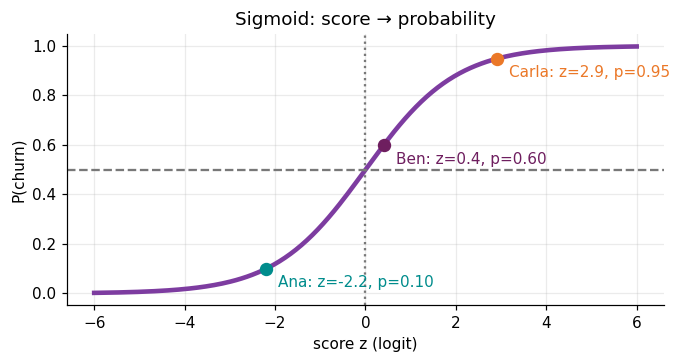

In [7]:
sigmoid = lambda z: 1 / (1 + np.exp(-z))
z = np.linspace(-6, 6, 200)
plt.figure(figsize=(7, 3.2))
plt.plot(z, sigmoid(z), color=PURPLE, lw=3)
plt.axhline(0.5, ls="--", color=GREY); plt.axvline(0, ls=":", color=GREY)
for name, zi, c in [("Ana", -2.2, TEAL), ("Ben", 0.4, PLUM), ("Carla", 2.9, ORANGE)]:
    plt.scatter(zi, sigmoid(zi), s=60, color=c, zorder=3)
    plt.annotate(f"{name}: z={zi}, p={sigmoid(zi):.2f}", (zi, sigmoid(zi)), xytext=(8, -12), textcoords="offset points", color=c)
plt.xlabel("score z (logit)"); plt.ylabel("P(churn)"); plt.title("Sigmoid: score → probability"); plt.show()

### 2.2 Binary cross-entropy: pay for surprise
$$L(y,\hat p)=-\big[\,y\log\hat p+(1-y)\log(1-\hat p)\,\big]$$
Only one term is active (the one of the true label). It is ~0 when the model is **right and sure**, and explodes when it is
**confidently wrong**. It is exactly the negative log-likelihood of the data (maximum likelihood).

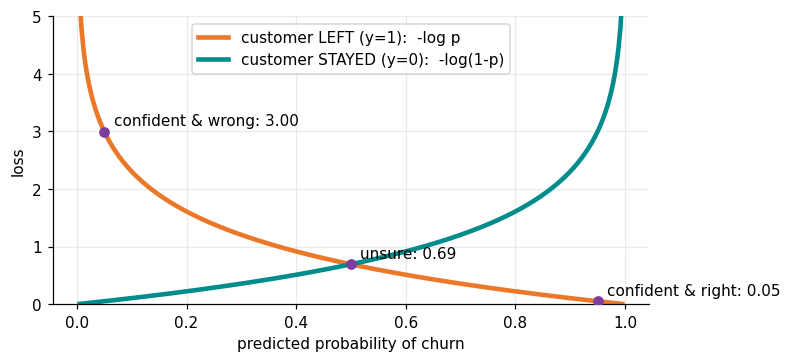

In [8]:
p = np.linspace(0.005, 0.995, 300)
plt.figure(figsize=(7, 3.4))
plt.plot(p, -np.log(p), color=ORANGE, lw=3, label="customer LEFT (y=1):  -log p")
plt.plot(p, -np.log(1 - p), color=TEAL, lw=3, label="customer STAYED (y=0):  -log(1-p)")
for pi, t in [(0.95, "confident & right"), (0.5, "unsure"), (0.05, "confident & wrong")]:
    plt.scatter(pi, -np.log(pi), color=PURPLE, zorder=3); plt.annotate(f"{t}: {-np.log(pi):.2f}", (pi, -np.log(pi)), xytext=(6, 4), textcoords="offset points")
plt.ylim(0, 5); plt.xlabel("predicted probability of churn"); plt.ylabel("loss"); plt.legend(); plt.show()

**Compute it by hand, then check with Keras.** Three customers who left, predicted 0.9, 0.6 and 0.2:

In [9]:
y_true = np.array([1., 1., 1.]); y_hat = np.array([0.9, 0.6, 0.2])
by_hand = -np.mean(y_true * np.log(y_hat) + (1 - y_true) * np.log(1 - y_hat))
by_keras = float(keras.losses.BinaryCrossentropy()(y_true, y_hat))
print(f"by hand: {by_hand:.4f}   keras: {by_keras:.4f}   (per customer: {np.round(-np.log(y_hat), 3)})")

by hand: 0.7419   keras: 0.7419   (per customer: [0.105 0.511 1.609])


E0000 00:00:1791967156.776950  100023 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


### 2.3 Why not mean squared error?
With a sigmoid output the gradient w.r.t. the logit is
* cross-entropy: $\partial L/\partial z=\hat p-y$
* MSE: $\partial L/\partial z=2(\hat p-y)\,\hat p(1-\hat p)$ → the extra factor is ≈0 when the sigmoid is saturated.

So MSE **stops learning exactly when the model is most wrong**:

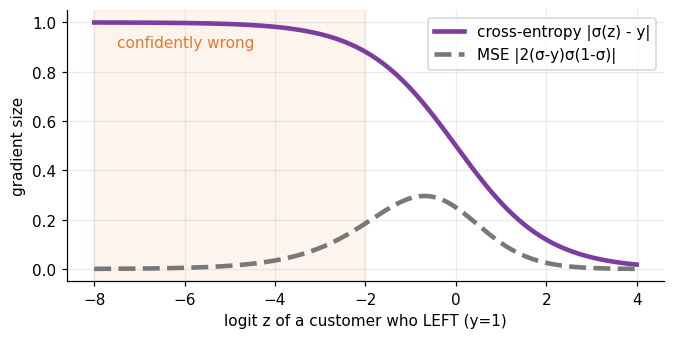

In [10]:
z = np.linspace(-8, 4, 300); s = sigmoid(z)
plt.figure(figsize=(7, 3.2))
plt.plot(z, np.abs(s - 1), color=PURPLE, lw=3, label="cross-entropy |σ(z) - y|")
plt.plot(z, np.abs(2 * (s - 1) * s * (1 - s)), color=GREY, lw=3, ls="--", label="MSE |2(σ-y)σ(1-σ)|")
plt.axvspan(-8, -2, color=ORANGE, alpha=0.08); plt.text(-7.5, 0.9, "confidently wrong", color=ORANGE)
plt.xlabel("logit z of a customer who LEFT (y=1)"); plt.ylabel("gradient size"); plt.legend(); plt.show()

### 2.4 The churn network
11 inputs → 32 ReLU → 16 ReLU → **1 sigmoid**. Rule to remember: **one output unit + sigmoid + binary cross-entropy**.

In [11]:
def build_mlp(units=(32, 16), act="relu", out=1, out_act="sigmoid", l2=0.0, dropout=0.0, bn=False,
              init="glorot_uniform", name=None):
    inp = keras.Input(shape=(X_train.shape[1],))
    x = inp
    for u in units:
        x = layers.Dense(u, kernel_initializer=init, use_bias=not bn,
                         kernel_regularizer=regularizers.l2(l2) if l2 else None)(x)
        if bn: x = layers.BatchNormalization()(x)
        x = layers.Activation(act)(x)
        if dropout: x = layers.Dropout(dropout)(x)
    return keras.Model(inp, layers.Dense(out, activation=out_act)(x), name=name)

def bin_metrics():
    return [keras.metrics.AUC(name="auc"), keras.metrics.Precision(name="precision"), keras.metrics.Recall(name="recall")]

keras.utils.set_random_seed(1)
model = build_mlp(name="churn_mlp")
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=bin_metrics())
model.summary()

Model: "churn_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 11)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 929 (3.63 KB)

 Trainable params: 929 (3.63 KB)

 Non-trainable params: 0 (0.00 B)

trained in 9s


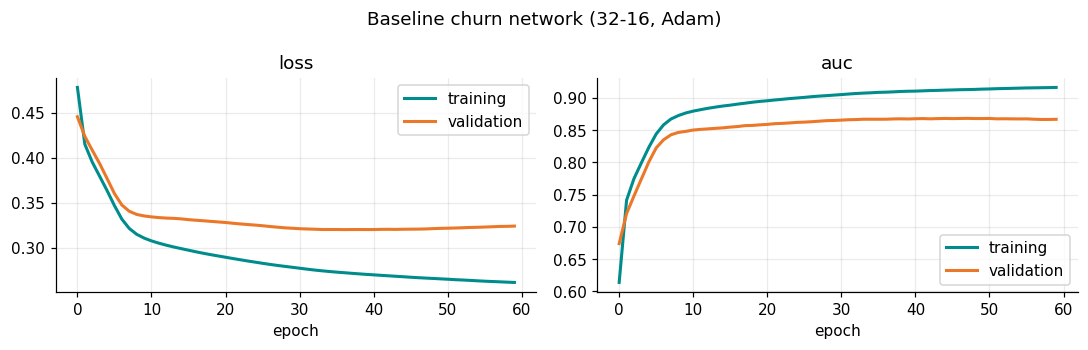

TEST  AUC 0.876 | accuracy 0.881 | recall@0.5 0.534


In [12]:
t0 = time.time()
hist = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=60, batch_size=64, verbose=0)
print(f"trained in {time.time()-t0:.0f}s")
plot_history(hist, "auc", "Baseline churn network (32-16, Adam)")
p_mlp = model.predict(X_test, verbose=0).ravel()
print(f"TEST  AUC {roc_auc_score(y_test, p_mlp):.3f} | accuracy {accuracy_score(y_test, p_mlp > .5):.3f} | "
      f"recall@0.5 {((p_mlp > .5) & (y_test == 1)).sum() / y_test.sum():.3f}")

> **Recap Part 2.** Sigmoid turns a score into a probability; binary cross-entropy charges $-\log$ of the probability given
> to the truth, and its gradient $\hat p - y$ never vanishes when the model is wrong. Our first network already beats the dumb
> baseline by a wide margin in AUC. Next: what if the answer has **more than two** options?

**Try it:** replace `loss="binary_crossentropy"` by `"mse"` and compare the validation AUC after 10 epochs.

---
## Part 3 — Multiclass classification: softmax + categorical cross-entropy

Second task: **which product should we offer next?** Four mutually exclusive classes → the target is a **one-hot** vector,
and the network outputs **4 logits**, one per class.

### 3.1 Softmax, step by step
$$p_k=\operatorname{softmax}(\mathbf z)_k=\frac{e^{z_k}}{\sum_j e^{z_j}}$$

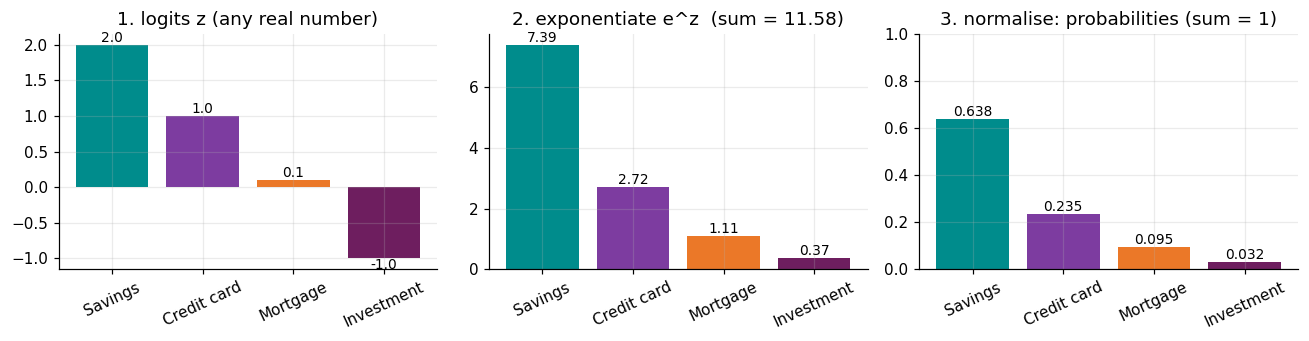

probabilities: [0.638 0.235 0.095 0.032] sum = 1.0


In [13]:
z = np.array([2.0, 1.0, 0.1, -1.0])            # logits for Savings, Credit card, Mortgage, Investment
e = np.exp(z); p = e / e.sum()
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
cols = [TEAL, PURPLE, ORANGE, PLUM]
bars(ax[0], z, PRODUCTS, cols, "1. logits z (any real number)", fmt="{:.1f}")
bars(ax[1], e, PRODUCTS, cols, f"2. exponentiate e^z  (sum = {e.sum():.2f})")
bars(ax[2], p, PRODUCTS, cols, "3. normalise: probabilities (sum = 1)", ylim=(0, 1), fmt="{:.3f}")
plt.tight_layout(); plt.show()
print("probabilities:", p.round(3), "sum =", p.sum())

### 3.2 Three properties of softmax
* **Only differences matter**: $\operatorname{softmax}(\mathbf z+c)=\operatorname{softmax}(\mathbf z)$. Libraries subtract $\max_k z_k$ so $e^z$ never overflows.
* **Temperature**: $\operatorname{softmax}(\mathbf z/T)$, small $T$ sharpens, large $T$ flattens (calibration, LLM sampling).
* **Sigmoid is softmax with two classes**: $\operatorname{softmax}(z_1,z_0)_1=\sigma(z_1-z_0)$.

shift invariance : [0.638 0.235 0.095 0.032] == [0.638 0.235 0.095 0.032]
naive exp(1000)  : inf -> that is why we subtract the max
2 classes        : softmax([1.3, 0])[0] = 0.7858   sigmoid(1.3) = 0.7858


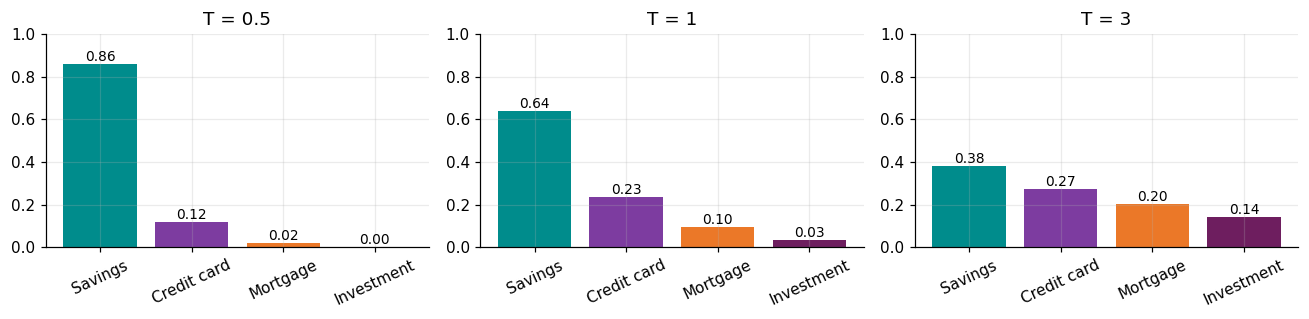

In [14]:
softmax = lambda v: np.exp(v - v.max()) / np.exp(v - v.max()).sum()
print("shift invariance :", softmax(z).round(3), "==", softmax(z + 100).round(3))
print("naive exp(1000)  :", np.exp(np.array([1000.0]))[0], "-> that is why we subtract the max")
print("2 classes        : softmax([1.3, 0])[0] =", softmax(np.array([1.3, 0.0]))[0].round(4), "  sigmoid(1.3) =", sigmoid(1.3).round(4))
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
for a, T in zip(ax, [0.5, 1, 3]):
    bars(a, softmax(z / T), PRODUCTS, cols, f"T = {T}", ylim=(0, 1))
plt.tight_layout(); plt.show()

### 3.3 Categorical cross-entropy
$$L(\mathbf y,\mathbf p)=-\sum_k y_k\log p_k=-\log p_{\text{true}}$$
Only the probability given to the **true class** counts. The true next product is a **Mortgage**:

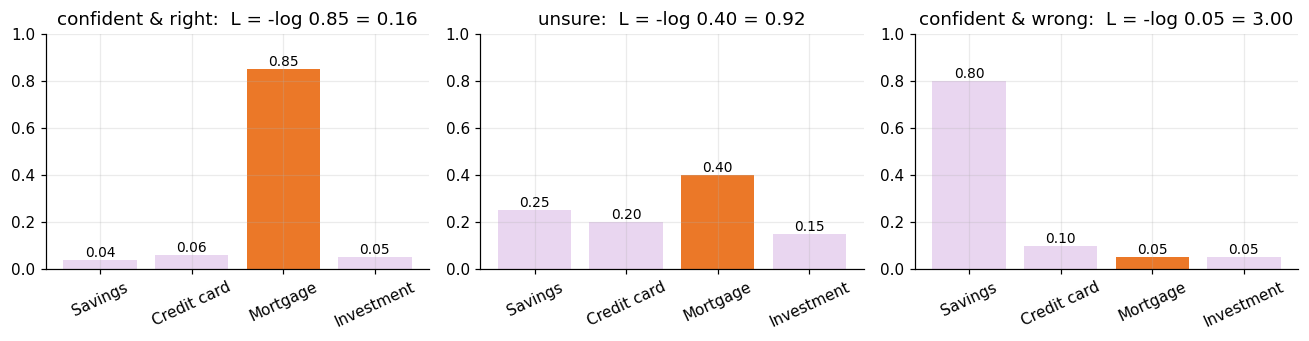

confident & right  by hand 0.163 | keras 0.163
unsure             by hand 0.916 | keras 0.916
confident & wrong  by hand 2.996 | keras 2.996


In [15]:
true = 2
preds = {"confident & right": [0.04, 0.06, 0.85, 0.05], "unsure": [0.25, 0.20, 0.40, 0.15],
         "confident & wrong": [0.80, 0.10, 0.05, 0.05]}
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
for a, (t, q) in zip(ax, preds.items()):
    q = np.array(q); c = [x if k == true else LILAC for k, x in enumerate(cols)]
    bars(a, q, PRODUCTS, c, f"{t}:  L = -log {q[true]:.2f} = {-np.log(q[true]):.2f}", ylim=(0, 1))
plt.tight_layout(); plt.show()
y_onehot = keras.utils.to_categorical([true], 4)
for t, q in preds.items():
    print(f"{t:18s} by hand {-np.log(q[true]):.3f} | keras {float(keras.losses.CategoricalCrossentropy()(y_onehot, np.array([q]))):.3f}")

### 3.4 Why softmax and cross-entropy belong together: the gradient is $\mathbf p-\mathbf y$
The exponential of softmax and the logarithm of cross-entropy cancel:
$$\frac{\partial L}{\partial z_k}=p_k-y_k$$
Let's **verify it numerically** with finite differences, no calculus required:

numerical gradient : [ 0.6381  0.2347 -0.9046  0.0318]
formula   p - y    : [ 0.6381  0.2347 -0.9046  0.0318]


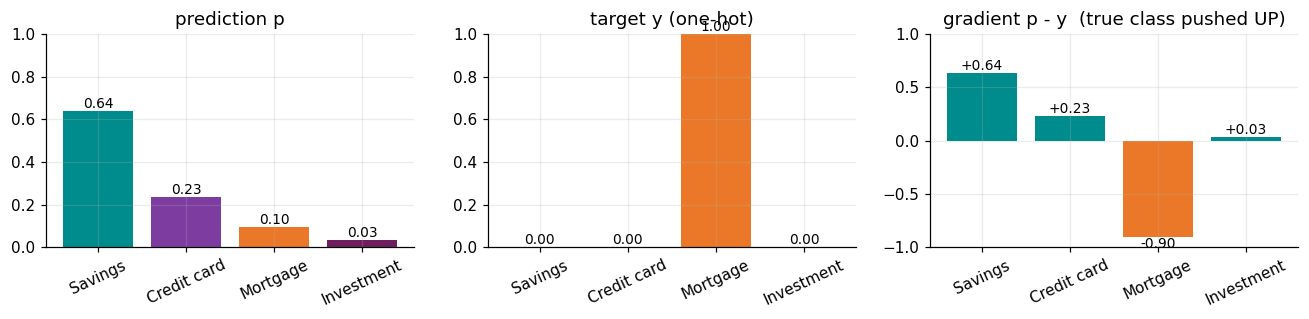

In [16]:
def ce_from_logits(zz, k_true): return -np.log(softmax(zz)[k_true])
eps, num_grad = 1e-6, []
for k in range(4):
    dz = np.zeros(4); dz[k] = eps
    num_grad.append((ce_from_logits(z + dz, true) - ce_from_logits(z - dz, true)) / (2 * eps))
y1 = np.eye(4)[true]
print("numerical gradient :", np.round(num_grad, 4))
print("formula   p - y    :", np.round(softmax(z) - y1, 4))
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
bars(ax[0], softmax(z), PRODUCTS, cols, "prediction p", ylim=(0, 1))
bars(ax[1], y1, PRODUCTS, cols, "target y (one-hot)", ylim=(0, 1))
g = softmax(z) - y1
bars(ax[2], g, PRODUCTS, [ORANGE if v < 0 else TEAL for v in g], "gradient p - y  (true class pushed UP)", ylim=(-1, 1), fmt="{:+.2f}")
plt.tight_layout(); plt.show()

### 3.5 Train the next-product network
Three equivalent ways to write it in Keras:

| targets | output layer | loss |
|---|---|---|
| one-hot `[0,0,1,0]` | `Dense(4, activation="softmax")` | `"categorical_crossentropy"` |
| integers `2` | `Dense(4, activation="softmax")` | `"sparse_categorical_crossentropy"` |
| integers `2` | `Dense(4)` (logits) | `SparseCategoricalCrossentropy(from_logits=True)`, the most stable |

We use the third one, and apply softmax ourselves when we need probabilities.

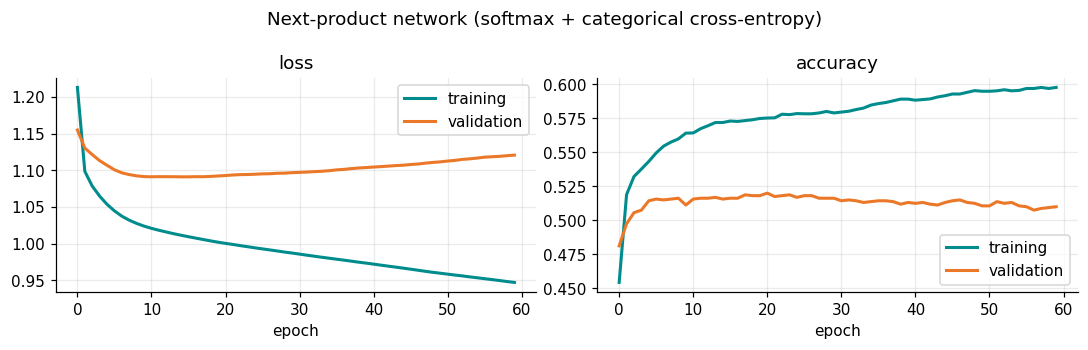

TEST accuracy 0.537 | log loss 1.088 | majority class 0.293


In [17]:
yp_train, yp_val, yp_test = y_prod[i_train], y_prod[i_val], y_prod[i_test]
keras.utils.set_random_seed(9)
multi = build_mlp(units=(64, 32), out=4, out_act=None, name="next_product")      # 4 logits, no activation
multi.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=["accuracy"])
h_multi = multi.fit(X_train, yp_train, validation_data=(X_val, yp_val), epochs=60, batch_size=64, verbose=0)
plot_history(h_multi, "accuracy", "Next-product network (softmax + categorical cross-entropy)")

P_test = keras.ops.convert_to_numpy(keras.ops.softmax(multi.predict(X_test, verbose=0)))
print(f"TEST accuracy {accuracy_score(yp_test, P_test.argmax(1)):.3f} | log loss {log_loss(yp_test, P_test):.3f} | "
      f"majority class {np.bincount(yp_test).max() / len(yp_test):.3f}")

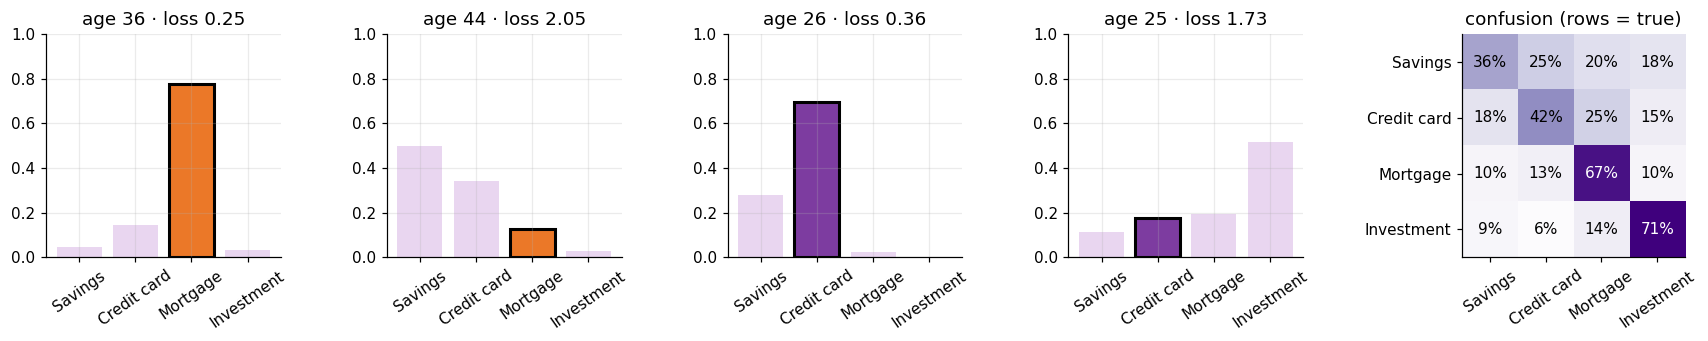

In [18]:
# probabilities for four test customers (true product outlined) + confusion matrix
fig, ax = plt.subplots(1, 5, figsize=(16, 3.2), gridspec_kw={"width_ratios": [1, 1, 1, 1, 1.4]})
for a, k in zip(ax[:4], range(4)):
    q, t = P_test[k], yp_test[k]
    b = a.bar(PRODUCTS, q, color=[c if j == t else LILAC for j, c in enumerate(cols)])
    b[t].set_edgecolor("black"); b[t].set_linewidth(2)
    a.set_ylim(0, 1); a.set_title(f"age {int(df.Age.iloc[i_test[k]])} · loss {-np.log(q[t]):.2f}"); a.tick_params(axis="x", rotation=35)
cm = confusion_matrix(yp_test, P_test.argmax(1), normalize="true")
ax[4].imshow(cm, cmap="Purples"); ax[4].set_xticks(range(4), PRODUCTS, rotation=35); ax[4].set_yticks(range(4), PRODUCTS)
for i in range(4):
    for j in range(4): ax[4].text(j, i, f"{cm[i, j]:.0%}", ha="center", va="center", color="white" if cm[i, j] > .45 else "black")
ax[4].set_title("confusion (rows = true)"); ax[4].grid(False)
plt.tight_layout(); plt.show()

> **Recap Part 3.** Softmax turns $K$ scores into $K$ probabilities that sum to 1; categorical cross-entropy is $-\log p_{\text{true}}$;
> together their gradient is simply $\mathbf p-\mathbf y$. Binary classification is the special case $K=2$.
> So far our networks are shallow. Next: what goes wrong when we stack many layers?

**Try it:** put `activation="sigmoid"` on the 4 outputs with a categorical loss. Do the probabilities still sum to 1?

---
## Part 4 — Deep networks that train: activations, vanishing gradients, initialization

### 4.1 Activation functions and their slopes
Backpropagation multiplies one slope $g'(z)$ **per layer**. The sigmoid's slope is at most **0.25**.

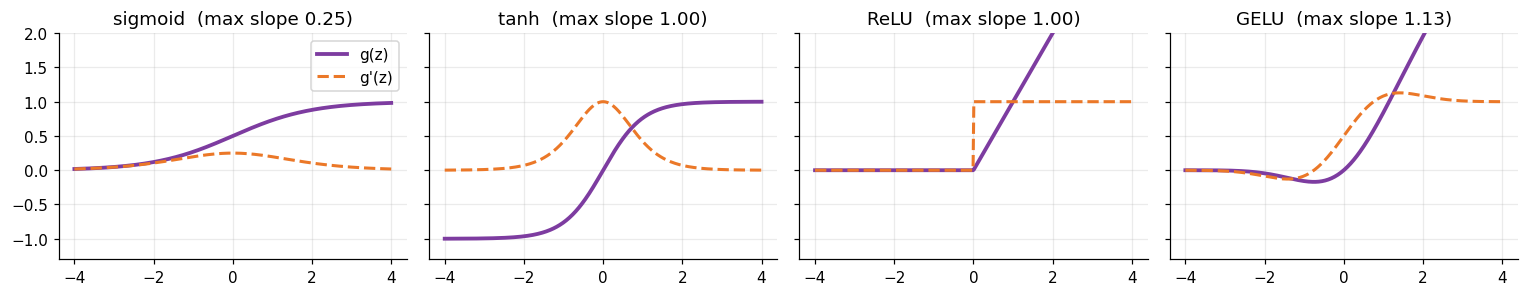

In [19]:
zz = np.linspace(-4, 4, 400)
gelu = lambda v: 0.5 * v * (1 + np.tanh(0.7978845608 * (v + 0.044715 * v ** 3)))
acts = {"sigmoid": (sigmoid(zz), sigmoid(zz) * (1 - sigmoid(zz))),
        "tanh": (np.tanh(zz), 1 - np.tanh(zz) ** 2),
        "ReLU": (np.maximum(0, zz), (zz > 0).astype(float)),
        "GELU": (gelu(zz), np.gradient(gelu(zz), zz))}
fig, ax = plt.subplots(1, 4, figsize=(14, 2.8), sharey=True)
for a, (n, (g, d)) in zip(ax, acts.items()):
    a.plot(zz, g, color=PURPLE, lw=2.5, label="g(z)"); a.plot(zz, d, color=ORANGE, lw=2, ls="--", label="g'(z)")
    a.set_title(f"{n}  (max slope {d.max():.2f})"); a.set_ylim(-1.3, 2)
ax[0].legend(); plt.tight_layout(); plt.show()

### 4.2 Vanishing gradients, measured
We build a **10-hidden-layer** network in plain NumPy, do one forward and one backward pass on 512 customers, and measure
the size of the gradient that reaches each layer. Sigmoid vs. ReLU, same data, same depth.

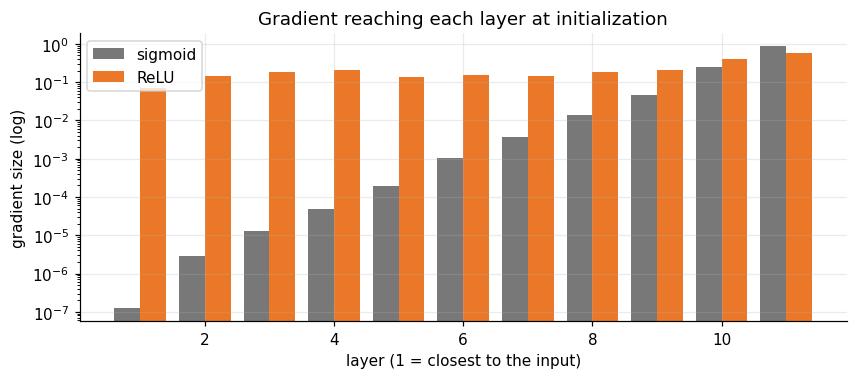

layer 1 gets 1.2e-07 with sigmoid and 0.07 with ReLU  ->  ~552,935x more


In [20]:
def layer_gradients(act="sigmoid", depth=10, width=32, seed=0):
    r = np.random.default_rng(seed)
    dims = [X_train.shape[1]] + [width] * depth + [1]
    # Glorot for sigmoid, He for ReLU (see 4.3)
    Ws = [r.standard_normal((a, b)) * (np.sqrt(2 / (a + b)) if act == "sigmoid" else np.sqrt(2 / a)) for a, b in zip(dims[:-1], dims[1:])]
    f  = sigmoid if act == "sigmoid" else (lambda v: np.maximum(0, v))
    df_ = (lambda v: sigmoid(v) * (1 - sigmoid(v))) if act == "sigmoid" else (lambda v: (v > 0).astype(float))
    xb, yb = X_train[:512], y_train[:512, None]
    hs, zs = [xb], []
    for W in Ws[:-1]:                                   # forward
        zs.append(hs[-1] @ W); hs.append(f(zs[-1]))
    p = sigmoid(hs[-1] @ Ws[-1])
    delta = (p - yb) / len(xb)                          # dL/dz at the output: p - y  (Part 2!)
    norms = [np.linalg.norm(hs[-1].T @ delta)]
    for l in range(depth - 1, -1, -1):                  # backward
        delta = (delta @ Ws[l + 1].T) * df_(zs[l])
        norms.append(np.linalg.norm(hs[l].T @ delta))
    return norms[::-1]                                  # layer 1 ... output

g_sig, g_relu = layer_gradients("sigmoid"), layer_gradients("relu")
k = np.arange(1, len(g_sig) + 1)
plt.figure(figsize=(9, 3.4))
plt.bar(k - 0.2, g_sig, 0.4, color=GREY, label="sigmoid"); plt.bar(k + 0.2, g_relu, 0.4, color=ORANGE, label="ReLU")
plt.yscale("log"); plt.xlabel("layer (1 = closest to the input)"); plt.ylabel("gradient size (log)"); plt.legend()
plt.title("Gradient reaching each layer at initialization"); plt.show()
print(f"layer 1 gets {g_sig[0]:.1e} with sigmoid and {g_relu[0]:.2f} with ReLU  ->  ~{g_relu[0]/g_sig[0]:,.0f}x more")

### 4.3 Weight initialization: keep the signal alive
Choose the scale of the random weights so the **variance of the activations** stays constant from layer to layer:

| name | $\mathrm{Var}(W)$ | for |
|---|---|---|
| Xavier / Glorot | $2/(n_{in}+n_{out})$ | tanh, sigmoid |
| He | $2/n_{in}$ | ReLU, GELU |

Below: activations of a 10-layer, 500-unit network for four choices (the classic CS231n experiment).

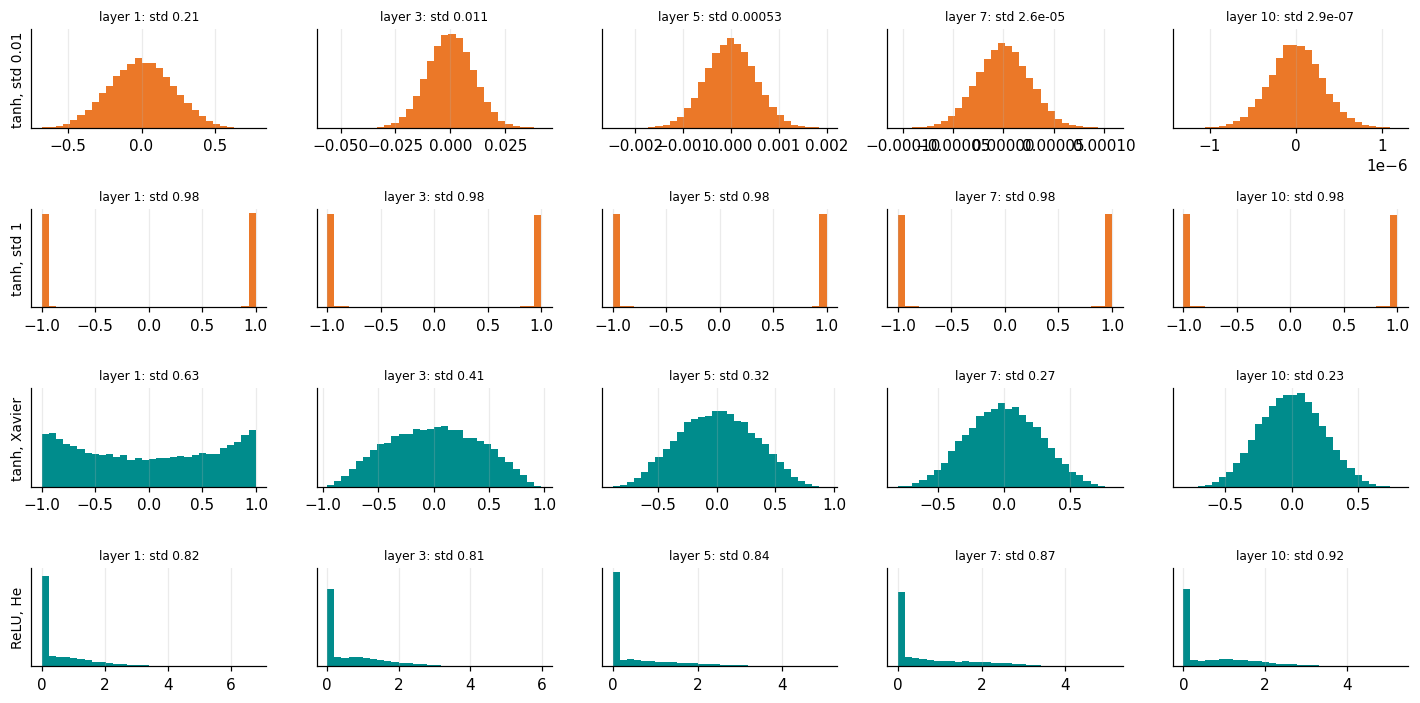

In [21]:
r = np.random.default_rng(0); H0 = r.standard_normal((1000, 500))
setups = [("tanh, std 0.01", np.tanh, 0.01), ("tanh, std 1", np.tanh, 1.0),
          ("tanh, Xavier", np.tanh, np.sqrt(1 / 500)), ("ReLU, He", lambda v: np.maximum(0, v), np.sqrt(2 / 500))]
fig, ax = plt.subplots(4, 5, figsize=(13, 6.5), sharey="row")
for i, (name, f, std) in enumerate(setups):
    h = H0
    for l in range(10):
        h = f(h @ (r.standard_normal((500, 500)) * std))
        if l in (0, 2, 4, 6, 9):
            j = (0, 2, 4, 6, 9).index(l)
            ax[i, j].hist(h.ravel()[::20], bins=30, color=TEAL if "Xavier" in name or "He" in name else ORANGE)
            ax[i, j].set_title(f"layer {l+1}: std {h.std():.2g}", fontsize=8); ax[i, j].set_yticks([])
    ax[i, 0].set_ylabel(name, fontsize=9)
plt.tight_layout(); plt.show()

> **Recap Part 4.** Gradients are products of per-layer slopes: sigmoids deep inside make them vanish, ReLU keeps them alive.
> Initialization sets the starting scale (He for ReLU, Xavier for tanh). In Keras: `Dense(64, activation="relu", kernel_initializer="he_normal")`.
> Now the gradient reaches every layer. Next: how do we **use** it to update the weights?

**Try it:** call `layer_gradients("sigmoid", depth=20)`. How small is the first layer's gradient now?

---
## Part 5 — Optimizers and learning-rate schedules

| optimizer | update | idea |
|---|---|---|
| SGD | $w\leftarrow w-\eta g$ | step downhill |
| Momentum | $m\leftarrow\beta m+g,\ w\leftarrow w-\eta m$ | a heavy ball keeps its speed |
| RMSprop | $v\leftarrow\rho v+(1-\rho)g^2,\ w\leftarrow w-\eta g/\sqrt v$ | smaller steps where gradients are large |
| Adam | momentum + RMSprop, bias-corrected | the default |
| AdamW | Adam, then $w\leftarrow w-\eta\lambda w$ | weight decay done right |

### 5.1 Watch them move on a narrow valley
Loss $=\tfrac12(0.25\,w_1^2+9\,w_2^2)$: steep in one direction, flat in the other, like real losses.

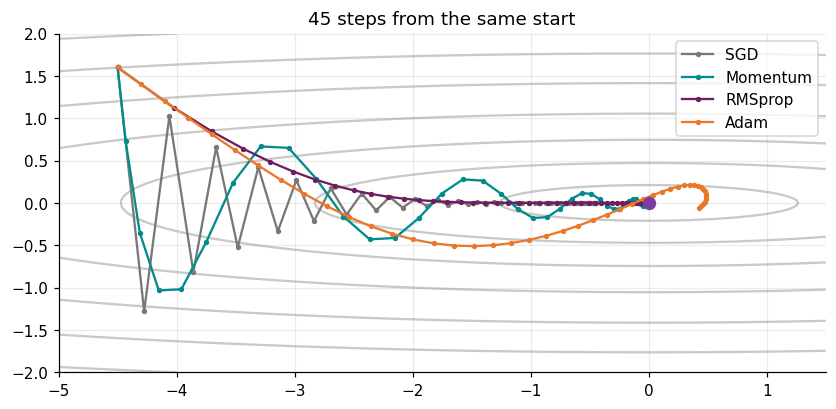

In [22]:
grad = lambda w: np.array([0.25 * w[0], 9 * w[1]])
def path(kind, steps=45):
    w, m, v, out = np.array([-4.5, 1.6]), np.zeros(2), np.zeros(2), []
    for t in range(1, steps + 1):
        out.append(w.copy()); g = grad(w)
        if kind == "SGD":        w = w - 0.20 * g
        if kind == "Momentum":   m = 0.8 * m + g; w = w - 0.06 * m
        if kind == "RMSprop":    v = 0.9 * v + 0.1 * g**2; w = w - 0.15 * g / (np.sqrt(v) + 1e-8)
        if kind == "Adam":
            m = 0.9 * m + 0.1 * g; v = 0.999 * v + 0.001 * g**2
            w = w - 0.20 * (m / (1 - 0.9**t)) / (np.sqrt(v / (1 - 0.999**t)) + 1e-8)
    return np.array(out + [w])
W1, W2 = np.meshgrid(np.linspace(-5, 1.5, 200), np.linspace(-2, 2, 200))
plt.figure(figsize=(9, 4))
plt.contour(W1, W2, 0.5 * (0.25 * W1**2 + 9 * W2**2), levels=[0.2, 1, 2.5, 5, 9, 14, 20], colors=GREY, alpha=0.4)
for kind, c in [("SGD", GREY), ("Momentum", TEAL), ("RMSprop", PLUM), ("Adam", ORANGE)]:
    P = path(kind); plt.plot(P[:, 0], P[:, 1], "-o", ms=2.5, color=c, label=kind, lw=1.5)
plt.scatter(0, 0, color=PURPLE, s=60, zorder=5); plt.legend(); plt.title("45 steps from the same start"); plt.show()

### 5.2 The optimizer race on churn
Same network, same initial weights, five optimizers:

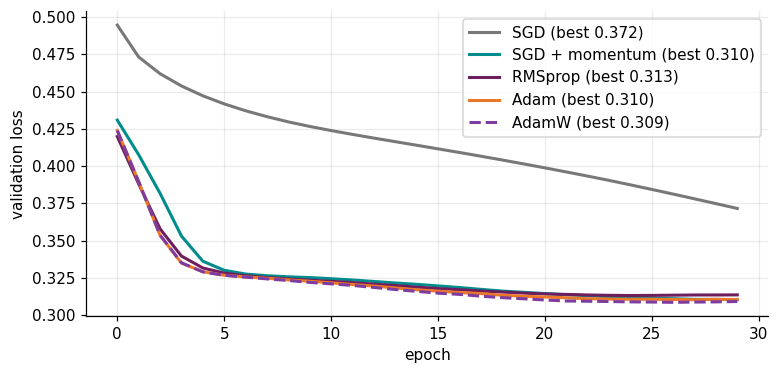

In [23]:
optims = {"SGD": lambda: keras.optimizers.SGD(0.01),
          "SGD + momentum": lambda: keras.optimizers.SGD(0.01, momentum=0.9),
          "RMSprop": lambda: keras.optimizers.RMSprop(1e-3),
          "Adam": lambda: keras.optimizers.Adam(1e-3),
          "AdamW": lambda: keras.optimizers.AdamW(1e-3, weight_decay=1e-2)}
race = {}
for name, make in optims.items():
    keras.utils.set_random_seed(4)
    m = build_mlp((64, 32)); m.compile(optimizer=make(), loss="binary_crossentropy", metrics=[keras.metrics.AUC(name="auc")])
    race[name] = m.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=30, batch_size=64, verbose=0).history
plt.figure(figsize=(8, 3.6))
for (name, h), c in zip(race.items(), [GREY, TEAL, PLUM, ORANGE, PURPLE]):
    plt.plot(h["val_loss"], color=c, lw=2, ls="--" if name == "AdamW" else "-", label=f"{name} (best {min(h['val_loss']):.3f})")
plt.xlabel("epoch"); plt.ylabel("validation loss"); plt.legend(); plt.show()

### 5.3 Learning-rate schedules
Big steps early to travel, small steps late to settle. Keras schedules are objects you can **evaluate** step by step:

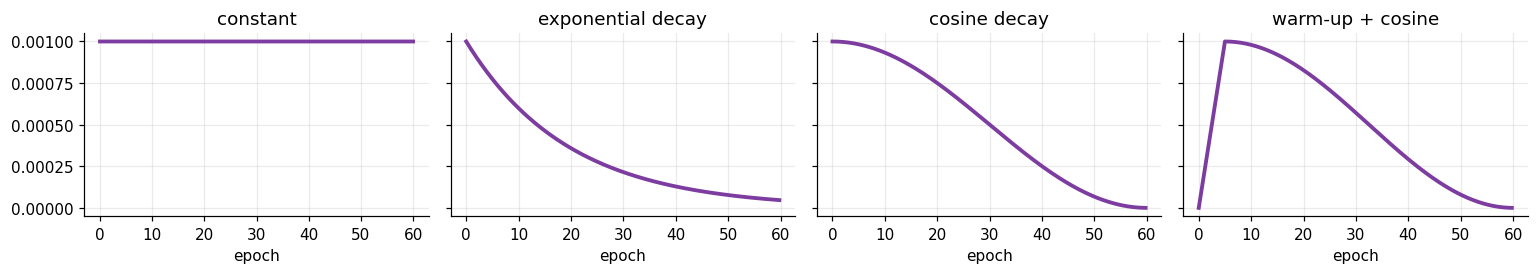

In [24]:
steps_per_epoch = int(np.ceil(len(X_train) / 64)); T = 60 * steps_per_epoch
s = np.arange(T)
schedules = {
    "constant": np.full(T, 1e-3),
    "exponential decay": keras.optimizers.schedules.ExponentialDecay(1e-3, decay_steps=steps_per_epoch, decay_rate=0.95),
    "cosine decay": keras.optimizers.schedules.CosineDecay(1e-3, decay_steps=T),
    "warm-up + cosine": keras.optimizers.schedules.CosineDecay(0.0, decay_steps=T - 5 * steps_per_epoch,
                                                               warmup_target=1e-3, warmup_steps=5 * steps_per_epoch)}
fig, ax = plt.subplots(1, 4, figsize=(14, 2.6), sharey=True)
for a, (n, sch) in zip(ax, schedules.items()):
    lr = sch if isinstance(sch, np.ndarray) else np.array([float(sch(i)) for i in s[::25]])
    a.plot((s if isinstance(sch, np.ndarray) else s[::25]) / steps_per_epoch, lr, color=PURPLE, lw=2.5); a.set_title(n); a.set_xlabel("epoch")
plt.tight_layout(); plt.show()

> **Recap Part 5.** Momentum smooths the zig-zags, RMSprop rescales each direction, Adam does both and is the sensible default;
> AdamW applies weight decay correctly. A schedule (or `ReduceLROnPlateau`, Part 8) shrinks the step size over time.
> Our networks now train well. Maybe *too* well. Next: training that **generalizes**.

**Try it:** set the SGD learning rate to 0.1 and to 0.001. Which one diverges, which one crawls?

---
## Part 6 — Training that generalizes: diagnose, then regularize

### 6.1 Under-fitting, good fit, over-fitting
Three model sizes trained on only **1,500 customers**, so over-fitting becomes visible:

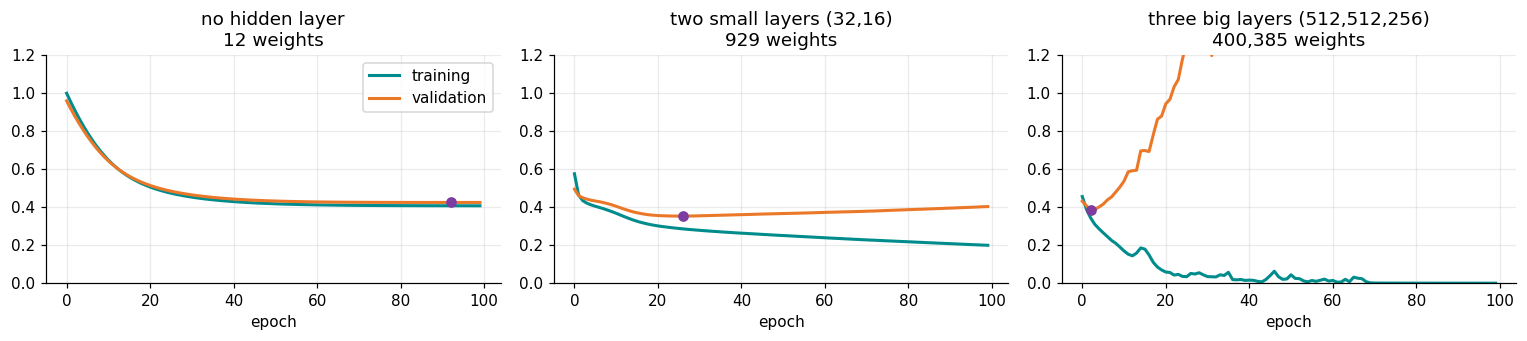

In [25]:
sub = np.random.default_rng(3).choice(len(y_train), 1500, replace=False)
sizes = {"no hidden layer": (), "two small layers (32,16)": (32, 16), "three big layers (512,512,256)": (512, 512, 256)}
fig, ax = plt.subplots(1, 3, figsize=(14, 3.2))
for a, (n, u) in zip(ax, sizes.items()):
    keras.utils.set_random_seed(2)
    m = build_mlp(u); m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy")
    h = m.fit(X_train[sub], y_train[sub], validation_data=(X_val, y_val), epochs=100, batch_size=32, verbose=0).history
    a.plot(h["loss"], color=TEAL, lw=2, label="training"); a.plot(h["val_loss"], color=ORANGE, lw=2, label="validation")
    best = int(np.argmin(h["val_loss"])); a.scatter(best, h["val_loss"][best], color=PURPLE, zorder=3)
    a.set_title(f"{n}\n{m.count_params():,} weights"); a.set_xlabel("epoch"); a.set_ylim(0, 1.2)
ax[0].legend(); plt.tight_layout(); plt.show()

**Reading the curves**

| you see | diagnosis | try |
|---|---|---|
| training high, validation close to it | under-fitting | bigger network, more epochs, better features |
| both low, small gap | good fit | stop, evaluate **once** on test |
| training keeps falling, validation rises | over-fitting | more data, L2, dropout, batch norm, early stopping |
| curves jump around | optimization | lower learning rate, bigger batch |

### 6.2 Three regularizers
* **L2 / weight decay**: $L_{\text{total}}=L+\lambda\sum w^2$, prefers small, spread-out weights.
* **Dropout**: switch off each unit with probability $p$ during training, an implicit ensemble.
* **Batch normalization**: normalise each unit over the batch, $\hat z=(z-\mu_B)/\sqrt{\sigma_B^2+\epsilon}$, then learn $\gamma\hat z+\beta$.

The race: a big network (256-256-128) on 2,000 customers, 80 epochs, **no early stopping** so we can see the decline.

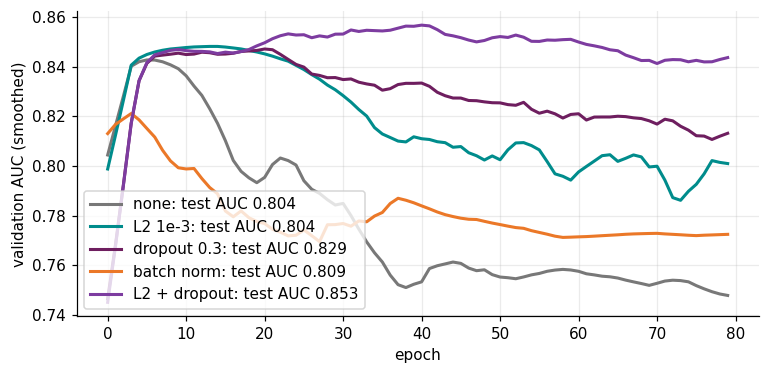

In [26]:
sub2 = np.random.default_rng(5).choice(len(y_train), 2000, replace=False)
configs = {"none": {}, "L2 1e-3": {"l2": 1e-3}, "dropout 0.3": {"dropout": 0.3}, "batch norm": {"bn": True},
           "L2 + dropout": {"l2": 1e-3, "dropout": 0.3}}
reg_models, reg_hist, reg_auc = {}, {}, {}
for n, kw in configs.items():
    keras.utils.set_random_seed(6)
    m = build_mlp((256, 256, 128), **kw)
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=[keras.metrics.AUC(name="auc")])
    reg_hist[n] = m.fit(X_train[sub2], y_train[sub2], validation_data=(X_val, y_val), epochs=80, batch_size=32, verbose=0).history
    reg_models[n], reg_auc[n] = m, roc_auc_score(y_test, m.predict(X_test, verbose=0).ravel())
smooth = lambda v, k=5: np.convolve(np.r_[[v[0]] * 2, v, [v[-1]] * 2], np.ones(k) / k, "valid")
plt.figure(figsize=(8, 3.6))
for (n, h), c in zip(reg_hist.items(), [GREY, TEAL, PLUM, ORANGE, PURPLE]):
    plt.plot(smooth(h["val_auc"]), color=c, lw=2, label=f"{n}: test AUC {reg_auc[n]:.3f}")
plt.xlabel("epoch"); plt.ylabel("validation AUC (smoothed)"); plt.legend(); plt.show()

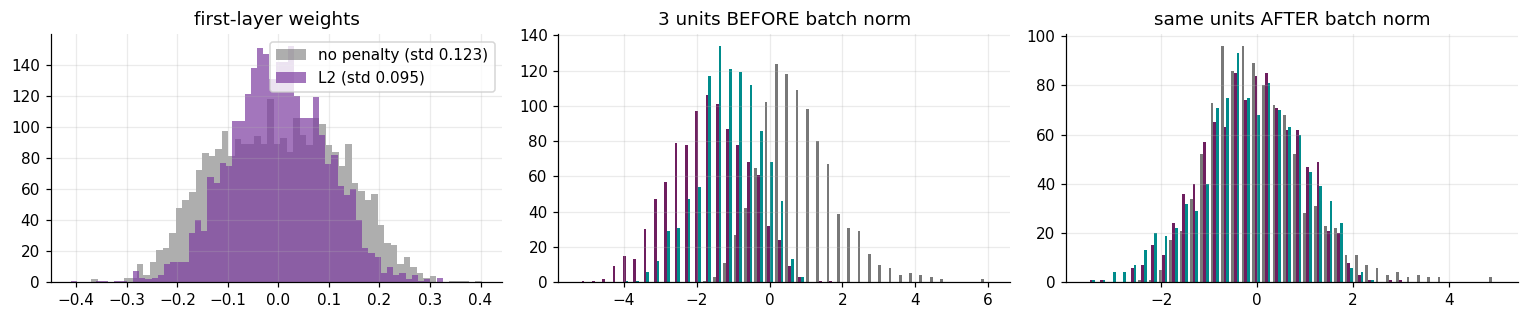

In [27]:
# What L2 does to the weights, and what batch norm does to the inputs of a layer
w_none = reg_models["none"].layers[1].get_weights()[0].ravel()
w_l2 = reg_models["L2 1e-3"].layers[1].get_weights()[0].ravel()
mb = reg_models["batch norm"]
dense2 = [l for l in mb.layers if isinstance(l, layers.Dense)][1]
bn2 = [l for l in mb.layers if isinstance(l, layers.BatchNormalization)][1]
pre, post = keras.Model(mb.input, [dense2.output, bn2.output]).predict(X_val[:1000], verbose=0)
fig, ax = plt.subplots(1, 3, figsize=(14, 3))
ax[0].hist(w_none, bins=60, color=GREY, alpha=0.6, label=f"no penalty (std {w_none.std():.3f})")
ax[0].hist(w_l2, bins=60, color=PURPLE, alpha=0.7, label=f"L2 (std {w_l2.std():.3f})"); ax[0].legend(); ax[0].set_title("first-layer weights")
ax[1].hist(pre[:, :3], bins=40, color=[GREY, PLUM, TEAL]); ax[1].set_title("3 units BEFORE batch norm")
ax[2].hist(post[:, :3], bins=40, color=[GREY, PLUM, TEAL]); ax[2].set_title("same units AFTER batch norm")
plt.tight_layout(); plt.show()

> **Recap Part 6.** The train/validation curves tell you what to do next. L2, dropout and batch norm each help a little;
> combined they help most. Early stopping (Part 8) adds the last line of defence.
> But a "better" model is only better under the right **metric**. Next: evaluating a problem where 80% of the answers are "no".

**Try it:** change the dropout rate to 0.5 and the L2 strength to 1e-2. Does the test AUC go up or down?

---
## Part 7 — Evaluating on imbalanced data

### 7.1 Confusion matrix, precision and recall
$$\text{Precision}=\frac{TP}{TP+FP}\ \text{(of the customers we call, how many were leaving?)}\qquad
\text{Recall}=\frac{TP}{TP+FN}\ \text{(of the leavers, how many did we find?)}$$

baseline MLP                 t=0.50 | acc 0.881 | precision 0.732 | recall 0.534 | AUC 0.876


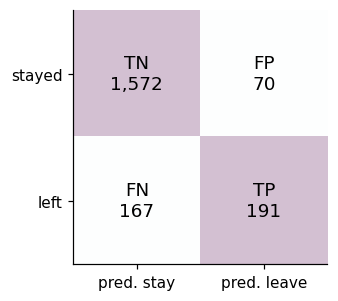

In [28]:
def report(y, p, t=0.5, name="model"):
    cm = confusion_matrix(y, p > t); tn, fp, fn, tp = cm.ravel()
    print(f"{name:28s} t={t:.2f} | acc {(tp+tn)/len(y):.3f} | precision {tp/max(tp+fp,1):.3f} | recall {tp/(tp+fn):.3f} | AUC {roc_auc_score(y, p):.3f}")
    return cm
cm = report(y_test, p_mlp, 0.5, "baseline MLP")
fig, ax = plt.subplots(figsize=(3.6, 3))
ax.imshow([[1, 0], [0, 1]], cmap="BuPu", alpha=0.25)
for (i, j), lab in zip([(0, 0), (0, 1), (1, 0), (1, 1)], ["TN", "FP", "FN", "TP"]):
    ax.text(j, i, f"{lab}\n{cm[i, j]:,}", ha="center", va="center", fontsize=12)
ax.set_xticks([0, 1], ["pred. stay", "pred. leave"]); ax.set_yticks([0, 1], ["stayed", "left"]); ax.grid(False); plt.show()

### 7.2 The threshold is a business decision
Lowering the threshold calls more customers: **recall up, precision down**.

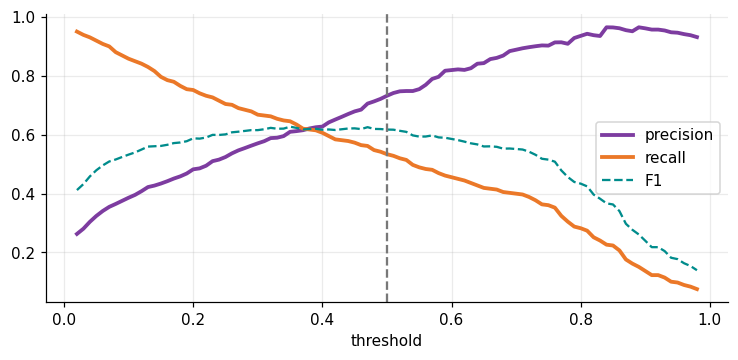

In [29]:
th = np.linspace(0.02, 0.98, 97)
prec = np.array([((p_mlp > t) & (y_test == 1)).sum() / max((p_mlp > t).sum(), 1) for t in th])
rec = np.array([((p_mlp > t) & (y_test == 1)).sum() / y_test.sum() for t in th])
plt.figure(figsize=(8, 3.4))
plt.plot(th, prec, color=PURPLE, lw=2.5, label="precision"); plt.plot(th, rec, color=ORANGE, lw=2.5, label="recall")
plt.plot(th, 2 * prec * rec / np.maximum(prec + rec, 1e-9), color=TEAL, ls="--", label="F1")
plt.axvline(0.5, color=GREY, ls="--"); plt.xlabel("threshold"); plt.legend(); plt.show()

### 7.3 ROC and precision–recall curves; the XGBoost and logistic-regression baselines
**AUC** = probability that a random leaver gets a higher score than a random stayer. It is independent of the threshold.
With rare positives the **PR curve** is more honest.

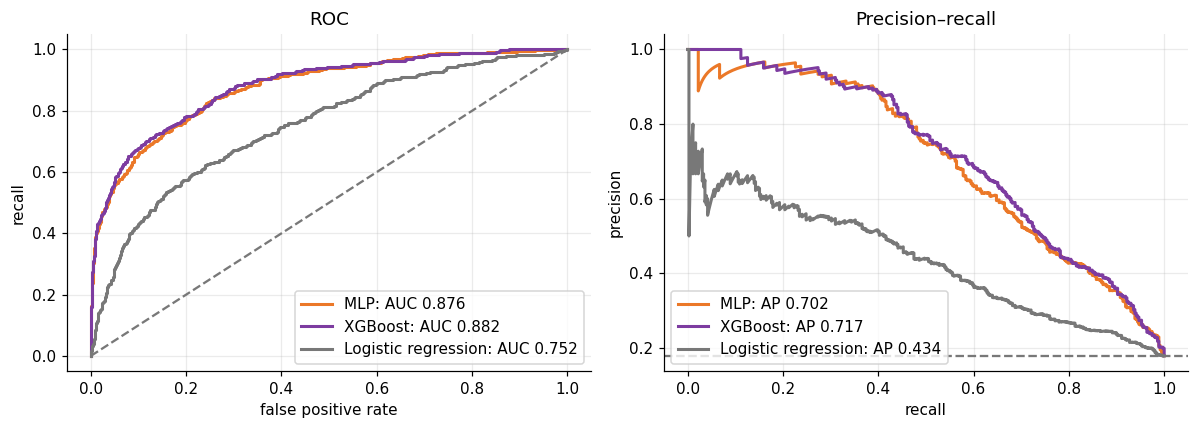

In [30]:
import xgboost as xgb
lr_model = LogisticRegression(max_iter=3000).fit(X_train, y_train)
xgb_model = xgb.XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.9,
                              colsample_bytree=0.9, eval_metric="logloss", random_state=0).fit(X_train, y_train)
scores = {"MLP": p_mlp, "XGBoost": xgb_model.predict_proba(X_test)[:, 1], "Logistic regression": lr_model.predict_proba(X_test)[:, 1]}
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for (n, s_), c in zip(scores.items(), [ORANGE, PURPLE, GREY]):
    f_, t_, _ = roc_curve(y_test, s_); pr_, rc_, _ = precision_recall_curve(y_test, s_)
    ax[0].plot(f_, t_, color=c, lw=2, label=f"{n}: AUC {roc_auc_score(y_test, s_):.3f}")
    ax[1].plot(rc_, pr_, color=c, lw=2, label=f"{n}: AP {average_precision_score(y_test, s_):.3f}")
ax[0].plot([0, 1], [0, 1], ls="--", color=GREY); ax[0].set_xlabel("false positive rate"); ax[0].set_ylabel("recall"); ax[0].set_title("ROC")
ax[1].axhline(y_test.mean(), ls="--", color=GREY); ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision"); ax[1].set_title("Precision–recall")
for a in ax: a.legend()
plt.tight_layout(); plt.show()

### 7.4 Class weights: make rare errors expensive
$w_c = n/(K\,n_c)$: each churner's error counts several times more in the loss.

In [31]:
n0, n1, n = (y_train == 0).sum(), (y_train == 1).sum(), len(y_train)
cw = {0: n / (2 * n0), 1: n / (2 * n1)}
print("class weights:", {k: round(float(v), 2) for k, v in cw.items()})
keras.utils.set_random_seed(1)
m_w = build_mlp(); m_w.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=bin_metrics())
m_w.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=60, batch_size=64, class_weight=cw, verbose=0)
p_w = m_w.predict(X_test, verbose=0).ravel()
_ = report(y_test, p_mlp, 0.5, "plain loss"); _ = report(y_test, p_w, 0.5, "class weights")

class weights: {0: 0.61, 1: 2.79}
plain loss                   t=0.50 | acc 0.881 | precision 0.732 | recall 0.534 | AUC 0.876
class weights                t=0.50 | acc 0.785 | precision 0.442 | recall 0.763 | AUC 0.877


### 7.5 Choose the threshold with money (on the **validation** set)
$$\text{cost}(t)=500\cdot FN(t)+50\cdot FP(t)$$
We pick $t$ on validation, then report it **once** on test, the honest procedure.

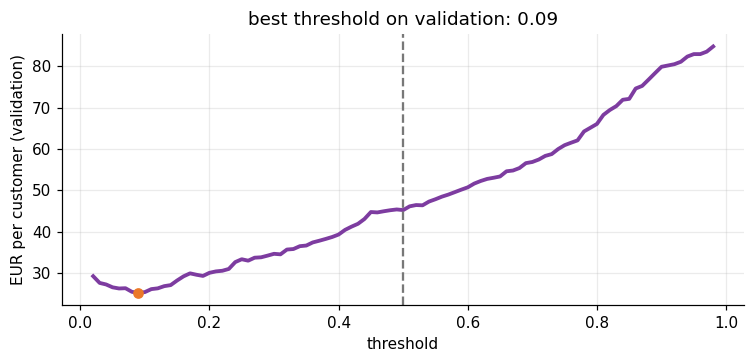

TEST threshold 0.5         :  43.50 EUR per customer
TEST best threshold 0.09   :  24.70 EUR per customer
TEST call nobody            :  89.50 EUR | call everybody:  41.05 EUR


In [32]:
COST_FN, COST_FP = 500, 50
cost = lambda y, p, t: (COST_FN * ((p <= t) & (y == 1)).sum() + COST_FP * ((p > t) & (y == 0)).sum()) / len(y)
p_val = model.predict(X_val, verbose=0).ravel()
cv = np.array([cost(y_val, p_val, t) for t in th]); t_best = th[cv.argmin()]
plt.figure(figsize=(8, 3.2)); plt.plot(th, cv, color=PURPLE, lw=2.5)
plt.scatter(t_best, cv.min(), color=ORANGE, zorder=3); plt.axvline(0.5, ls="--", color=GREY)
plt.xlabel("threshold"); plt.ylabel("EUR per customer (validation)"); plt.title(f"best threshold on validation: {t_best:.2f}"); plt.show()
for name, t in [("threshold 0.5", 0.5), (f"best threshold {t_best:.2f}", t_best)]:
    print(f"TEST {name:22s}: {cost(y_test, p_mlp, t):6.2f} EUR per customer")
print(f"TEST call nobody            : {cost(y_test, p_mlp, 1.01):6.2f} EUR | call everybody: {cost(y_test, p_mlp, -0.01):6.2f} EUR")

> **Recap Part 7.** With imbalanced classes, accuracy hides failure. Precision and recall answer business questions; ROC-AUC
> ranks, PR curves show the cost of finding rare cases. Class weights and moving the threshold do a similar job, and the
> threshold is best chosen with **money**, on validation data. Next: let Keras do the watching for us, and compare with trees.

---
## Part 8 — Callbacks, TensorBoard and the XGBoost baseline

### 8.1 Callbacks: code that runs during training
* **EarlyStopping**: stop when validation stops improving (and restore the best weights)
* **ModelCheckpoint**: save the best model to disk
* **ReduceLROnPlateau**: halve the learning rate on a plateau
* **TensorBoard**: log every run to compare them visually

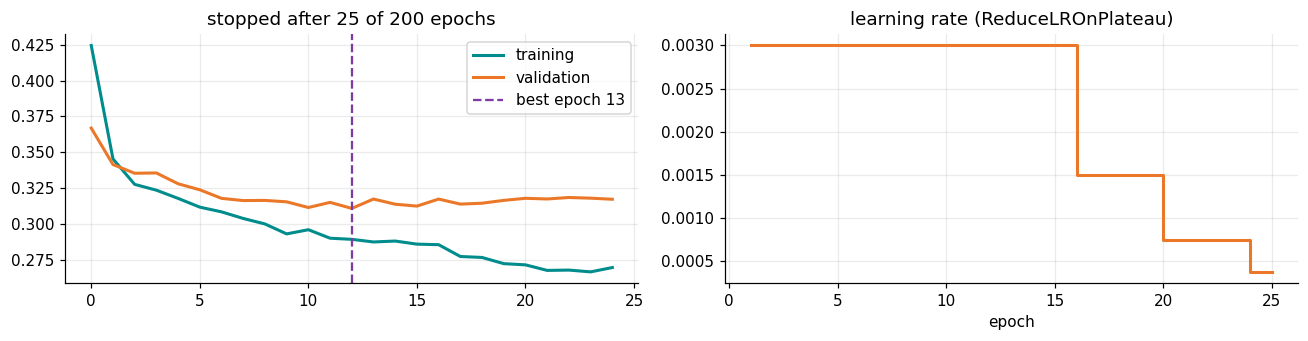

In [33]:
os.makedirs("logs", exist_ok=True)
lrs = []
class LRLogger(keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        lrs.append(float(keras.ops.convert_to_numpy(self.model.optimizer.learning_rate)))
callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=12, restore_best_weights=True),
             keras.callbacks.ModelCheckpoint("churn_best.keras", monitor="val_auc", mode="max", save_best_only=True),
             keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5),
             LRLogger()]
import importlib.util                    # TensorBoard logging needs TensorFlow (present in Colab and Kaggle)
if importlib.util.find_spec("tensorflow"):
    callbacks.append(keras.callbacks.TensorBoard(log_dir="logs/churn_callbacks"))
else:
    print("TensorFlow not installed here: TensorBoard logging skipped")
keras.utils.set_random_seed(11)
m_cb = build_mlp((128, 64), dropout=0.2)
m_cb.compile(optimizer=keras.optimizers.Adam(3e-3), loss="binary_crossentropy", metrics=bin_metrics())
h_cb = m_cb.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=200, batch_size=64, callbacks=callbacks, verbose=0)
best = int(np.argmin(h_cb.history["val_loss"]))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
ax[0].plot(h_cb.history["loss"], color=TEAL, lw=2, label="training"); ax[0].plot(h_cb.history["val_loss"], color=ORANGE, lw=2, label="validation")
ax[0].axvline(best, color=PURPLE, ls="--", label=f"best epoch {best+1}"); ax[0].legend(); ax[0].set_title(f"stopped after {len(lrs)} of 200 epochs")
ax[1].step(range(1, len(lrs) + 1), lrs, color=ORANGE, lw=2); ax[1].set_title("learning rate (ReduceLROnPlateau)"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

### 8.2 TensorBoard
Run the cell below to open the dashboard inside the notebook. Each folder under `logs/` is one run.
The cell first stops any TensorBoard left over from a previous run: an old one still holding the port is what causes
the error *"Timed out waiting for TensorBoard to start"*.

In [34]:
# TensorBoard inside the notebook (Colab, Kaggle or local Jupyter).
# Re-running this cell used to fail with "Timed out waiting for TensorBoard to start":
# an old TensorBoard from a previous run still held the port. We stop old ones first.
import os, glob, signal, shutil, tempfile
try:
    from tensorboard import manager
    for info in manager.get_all():                        # stop TensorBoards left from earlier runs
        try:
            os.kill(info.pid, signal.SIGTERM)
        except OSError:
            pass
    shutil.rmtree(os.path.join(tempfile.gettempdir(), ".tensorboard-info"), ignore_errors=True)

    if not glob.glob("logs/**/events.out.tfevents*", recursive=True):
        print("No TensorBoard logs yet: run the callbacks cell (8.1) first, with TensorFlow installed.")
    else:
        ip = get_ipython()
        ip.run_line_magic("reload_ext", "tensorboard")    # works whether or not it was loaded before
        ip.run_line_magic("tensorboard", "--logdir logs --port 6007")
except ModuleNotFoundError:
    print("TensorBoard is not installed here. In Colab/Kaggle it is; locally: pip install tensorboard")
# If it still times out on a local machine, open a terminal and run:  tensorboard --logdir logs
# then browse to http://localhost:6006

ERROR: Timed out waiting for TensorBoard to start. It may still be running as pid 193495.

### 8.3 Does the network beat XGBoost?

In [35]:
xgb_multi = xgb.XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.05, random_state=0).fit(X_train, yp_train)
lr_multi = LogisticRegression(max_iter=4000).fit(X_train, yp_train)
p_cb = m_cb.predict(X_test, verbose=0).ravel()
rows = []
for name, pb, pm in [("Logistic regression", scores["Logistic regression"], lr_multi.predict_proba(X_test)),
                     ("XGBoost", scores["XGBoost"], xgb_multi.predict_proba(X_test)),
                     ("MLP (baseline, Part 2/3)", p_mlp, P_test),
                     ("MLP + callbacks (Part 8)", p_cb, None)]:
    rows.append({"model": name, "churn AUC": roc_auc_score(y_test, pb), "churn log loss": log_loss(y_test, pb),
                 "product accuracy": accuracy_score(yp_test, pm.argmax(1)) if pm is not None else np.nan,
                 "product log loss": log_loss(yp_test, pm) if pm is not None else np.nan})
pd.DataFrame(rows).set_index("model").round(3)

,churn AUC,churn log loss,product accuracy,product log loss
model,,,,
Logistic regression,0.752,0.406,0.536,1.088
XGBoost,0.882,0.296,0.546,1.056
"MLP (baseline, Part 2/3)",0.876,0.310,0.538,1.088
MLP + callbacks (Part 8),0.882,0.300,NaN,NaN


> **Recap Part 8.** Callbacks automate early stopping, checkpointing and learning-rate cuts; TensorBoard lets you compare runs.
> On small **tabular** data, gradient-boosted trees usually match or beat a network, so always run them first. Networks win on
> images, sound and text, which is where the course goes next (Session 4: CNNs).

---
## Summary: the whole session in seven lines
1. Binary → 1 **sigmoid** output + **binary cross-entropy**. Multiclass → $K$ logits + **softmax** + **categorical cross-entropy**.
2. Cross-entropy $=-\log$(probability of the truth); with softmax/sigmoid its gradient is $\mathbf p-\mathbf y$.
3. Hidden layers: **ReLU/GELU** with **He** init; deep sigmoids make gradients vanish.
4. Start with **Adam** (AdamW with weight decay) and a schedule or `ReduceLROnPlateau`.
5. Read the curves; fight over-fitting with **L2, dropout, batch norm, early stopping**.
6. With imbalanced classes use **precision, recall, ROC/PR**, and choose the threshold with the business cost on validation.
7. Always compare with a **tree baseline** on tabular data.

## Challenge 2: save the customers
Upload the real `Churn_Modelling.csv` (Kaggle) next to this notebook and re-run everything. Then:
* improve the churn network (architecture, regularization, optimizer), logging every run to TensorBoard;
* report test AUC, the PR curve, and the cost of your chosen threshold vs. "call everybody" and "call nobody";
* explain in one slide whether you would deploy the MLP or XGBoost, and why.